# T2ICount - full FSC147-S spatial diagnostic (230 images)

All 230 images x BASE-002 / RP-003 / RP-009 x class / saved detailed prompts:
**1,380 inference conditions**. Counting and paired intermediate-map metrics use all
images. Only the original fixed 20 retain detailed figures and native token-map NPZs.
Other maps use a private local cache, cleaned on success and Python exceptions.

Source comes directly from the GitHub `rich-prompt-alignment` branch **after the
reviewed files have been committed and pushed by the researcher**. No source ZIP.
The exact resolved Git commit is verified and recorded. Prompt banks, models and data
remain external assets on Drive; saved detailed prompts are never regenerated.

The existing preliminary is reused if valid; it is never overwritten. Both inference
switches default to False. Enable RUN_PRELIMINARY only if needed, review its report,
then enable RUN_DIAGNOSTIC. Existing partial runs require a new output directory.
No training or scientific conclusion update. Dot metrics remain unavailable.


In [1]:
from pathlib import Path
import os, sys, json, subprocess, hashlib, shutil, tempfile, zipfile, re

ASSET_ROOT = Path('/content/drive/MyDrive/T2ICount-assets')
OUTPUT_DIR = ASSET_ROOT / 'outputs/spatial_diagnostic_v2_all230'
NUM_IMAGES = 230
VISUALIZE_FIRST_N = 20
MODEL_SELECTION = ['BASE-002', 'RP-003', 'RP-009']
PROMPT_SELECTION = ['class', 'detailed']
RUN_DIAGNOSTIC = True
RUN_PRELIMINARY = False
PRELIMINARY_OUTPUT_DIR = ASSET_ROOT / 'outputs/spatial_diagnostic_v1_preliminary'
RUNTIME_ASSET_ROOT = Path('/content/T2ICount-assets')
ASSET_ZIP = Path('/content/drive/MyDrive/T2ICount-assets.zip')
LOCAL_CACHE_PARENT = Path('/content')
REPO = Path('/content/T2ICount-SpatialDiagnostic230-GitHub')
REPO_URL = 'https://github.com/bqa100507-spec/T2ICount-Implementation.git'
SOURCE_BRANCH = 'rich-prompt-alignment'
# Optional full commit SHA after review/push. Empty resolves and pins the branch tip
# once per notebook session; subsequent cells refuse a changed local revision.
EXPECTED_COMMIT = ''
SOURCE_REVISION = None
PROMPT_BANK = ASSET_ROOT / 'prompts/fsc147s_gemma4_26b_v3.json'
INSTALL_DEPENDENCIES = True
PATCH_BATCH_SIZE = 1
CAPTURE_IMAGE = '3319.jpg'
EXPECTED_IMAGE_IDS = ['3319.jpg', '7706.jpg', '918.jpg', '31.jpg', '605.jpg', '290.jpg', '343.jpg', '336.jpg', '6305.jpg', '3169.jpg', '6353.jpg', '3721.jpg', '3699.jpg', '3019.jpg', '5651.jpg', '63.jpg', '3287.jpg', '75.jpg', '3703.jpg', '5356.jpg', '3312.jpg', '4792.jpg', '686.jpg', '2672.jpg', '4115.jpg', '250.jpg', '913.jpg', '2261.jpg', '5426.jpg', '5545.jpg', '3209.jpg', '717.jpg', '232.jpg', '244.jpg', '6894.jpg', '461.jpg', '2415.jpg', '50.jpg', '894.jpg', '909.jpg', '2724.jpg', '6405.jpg', '2245.jpg', '2143.jpg', '2719.jpg', '2715.jpg', '4802.jpg', '7526.jpg', '4102.jpg', '2076.jpg', '252.jpg', '4851.jpg', '20.jpg', '65.jpg', '1999.jpg', '4058.jpg', '705.jpg', '4130.jpg', '19.jpg', '2989.jpg', '265.jpg', '3870.jpg', '5231.jpg', '4825.jpg', '542.jpg', '4114.jpg', '910.jpg', '3013.jpg', '6638.jpg', '3251.jpg', '778.jpg', '486.jpg', '3087.jpg', '3108.jpg', '3191.jpg', '2322.jpg', '5194.jpg', '2826.jpg', '2872.jpg', '2998.jpg', '2068.jpg', '1930.jpg', '6604.jpg', '2760.jpg', '2460.jpg', '539.jpg', '76.jpg', '2172.jpg', '4788.jpg', '3204.jpg', '3733.jpg', '2090.jpg', '5849.jpg', '54.jpg', '243.jpg', '7647.jpg', '210.jpg', '695.jpg', '90.jpg', '723.jpg', '3313.jpg', '2052.jpg', '5943.jpg', '5457.jpg', '773.jpg', '6589.jpg', '4109.jpg', '3690.jpg', '6654.jpg', '4177.jpg', '83.jpg', '4752.jpg', '4466.jpg', '5388.jpg', '5669.jpg', '5203.jpg', '4128.jpg', '5887.jpg', '2096.jpg', '759.jpg', '4105.jpg', '27.jpg', '1901.jpg', '3036.jpg', '3154.jpg', '3023.jpg', '3981.jpg', '2796.jpg', '4481.jpg', '3241.jpg', '4103.jpg', '734.jpg', '890.jpg', '6107.jpg', '2184.jpg', '2145.jpg', '2244.jpg', '3257.jpg', '2710.jpg', '2348.jpg', '3111.jpg', '428.jpg', '6266.jpg', '6991.jpg', '2053.jpg', '711.jpg', '2042.jpg', '5415.jpg', '2611.jpg', '6158.jpg', '2303.jpg', '3114.jpg', '3105.jpg', '296.jpg', '2745.jpg', '3007.jpg', '706.jpg', '4892.jpg', '91.jpg', '737.jpg', '5061.jpg', '735.jpg', '621.jpg', '5416.jpg', '2840.jpg', '5834.jpg', '2808.jpg', '3411.jpg', '6247.jpg', '241.jpg', '4864.jpg', '214.jpg', '376.jpg', '3143.jpg', '698.jpg', '7060.jpg', '3779.jpg', '3308.jpg', '1074.jpg', '5646.jpg', '599.jpg', '7367.jpg', '7530.jpg', '2162.jpg', '3118.jpg', '216.jpg', '7249.jpg', '6824.jpg', '5854.jpg', '4921.jpg', '6087.jpg', '6300.jpg', '239.jpg', '7584.jpg', '81.jpg', '7377.jpg', '2681.jpg', '4769.jpg', '2985.jpg', '6841.jpg', '4332.jpg', '3850.jpg', '5916.jpg', '3180.jpg', '268.jpg', '772.jpg', '2746.jpg', '264.jpg', '413.jpg', '3106.jpg', '6360.jpg', '77.jpg', '2566.jpg', '6245.jpg', '600.jpg', '914.jpg', '846.jpg', '191.jpg', '436.jpg', '261.jpg', '2062.jpg', '3104.jpg', '201.jpg', '803.jpg', '7.jpg', '2282.jpg', '2280.jpg', '374.jpg', '372.jpg', '381.jpg']
VISUALIZATION_IMAGE_IDS = ['3319.jpg', '7706.jpg', '918.jpg', '31.jpg', '605.jpg', '290.jpg', '343.jpg', '336.jpg', '6305.jpg', '3169.jpg', '6353.jpg', '3721.jpg', '3699.jpg', '3019.jpg', '5651.jpg', '63.jpg', '3287.jpg', '75.jpg', '3703.jpg', '5356.jpg']
EXPECTED_METADATA_SHA256 = '7040090d0d4c8805646a7e392dc23b7b7c87ffdc4b03019d06f3aeaa3130a51e'
EXPECTED_BANK_SHA256 = '1c0c87ff686618bcb008b5fc077e994b3144ac3bb71c448411a00a261bfcc89c'

def stream(command, cwd=None):
    print('+', ' '.join(map(str, command)), flush=True)
    process = subprocess.Popen(list(map(str, command)), cwd=cwd, stdout=subprocess.PIPE,
                               stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in process.stdout:
        print(line, end='', flush=True)
    code = process.wait()
    if code:
        raise subprocess.CalledProcessError(code, command)

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream_file:
        for chunk in iter(lambda: stream_file.read(1024*1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


## 1. Mount Google Drive and inspect available runtime

A GPU is only required when a **new** inference run is necessary. Reading completed outputs works even after the old Colab GPU session has ended.


In [2]:
print('Python:', sys.version.split()[0])
drive_mount = Path('/content/drive')
if not (drive_mount / 'MyDrive').is_dir():
    from google.colab import drive
    drive.mount(str(drive_mount))
assert ASSET_ROOT.is_dir(), f'Asset root missing: {ASSET_ROOT}'
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TRANSFORMERS_OFFLINE'] = '1'
os.environ.pop('SSLKEYLOGFILE', None)
print('Drive ready:', ASSET_ROOT)


Mounted at /content/drive
Drive ready: /content/drive/MyDrive/T2ICount-assets


In [3]:
"""Standard-library-only output checks shared with the notebook (no model imports)."""
import csv
import json
import math
from pathlib import Path

MAP_TYPES = ('fused_attention', 'sim_x2', 'sim_x1', 'density_native',
             'attention_12', 'attention_24', 'attention_48')


def comparison_keys(image_ids, models, prompts):
    conditions = [(model, prompt) for model in models for prompt in prompts]
    return {(image, *left, *right, kind)
            for image in image_ids
            for i, left in enumerate(conditions) for right in conditions[i+1:]
            if left[0] == right[0] or left[1] == right[1]
            for kind in MAP_TYPES}


def saved_run_state(folder, expected_images, models, prompts, expected_ids,
                    visualization_ids, capture_image='3319.jpg', require_complete=True):
    """Check coverage, not 1380 equivalence tests: only six on designated image.

    Legacy v1 preliminary outputs are accepted without the v2 storage fields.
    Full v2 output additionally requires all paired metrics, exact retained files,
    and a removed local cache. No inference/weights/dataset access is performed.
    """
    folder = Path(folder)
    if not folder.exists():
        return False, 'not found'
    try:
        manifest = json.loads((folder / 'manifest.json').read_text(encoding='utf-8'))
        summary = json.loads((folder / 'summary.json').read_text(encoding='utf-8'))
        with (folder / 'results.csv').open(newline='', encoding='utf-8') as stream:
            rows = list(csv.DictReader(stream))
        valid_status = ('complete',) if require_complete else ('running', 'complete')
        if manifest.get('status') not in valid_status or summary.get('status') != 'complete':
            return False, 'manifest/summary is incomplete'
        config = manifest['config']
        if config['models'] != models or config['prompts'] != prompts or config['num_images'] != expected_images:
            return False, 'model/prompt/image-count configuration mismatch'
        selected = manifest['selected_images']
        image_ids = [record['image'] for record in selected]
        if (len(image_ids) != expected_images or len(set(image_ids)) != expected_images
                or image_ids != list(expected_ids)):
            return False, 'evaluated image identities/order mismatch'
        capture = manifest['capture_equivalence']
        capture_keys = {(r['model'], r['image'], r['prompt']) for r in capture}
        expected_capture = {(model, capture_image, prompt) for model in models for prompt in prompts}
        if (len(capture) != len(expected_capture) or capture_keys != expected_capture
                or not all(r['bitwise_equal'] is True for r in capture)):
            return False, 'designated preliminary image capture equivalence incomplete/failed'
        expected_rows = {(m, image, p) for m in models for image in image_ids for p in prompts}
        row_keys = {(r['model'], r['image'], r['prompt_type']) for r in rows}
        if len(rows) != len(expected_rows) or row_keys != expected_rows:
            return False, 'counting condition coverage mismatch'
        if any(not math.isfinite(float(r[k])) for r in rows for k in ('gt_count', 'pred_count', 'abs_error')):
            return False, 'nonfinite counting value'
        counts = summary['counting']
        if (len(counts) != len(models)*len(prompts)
                or {(r['model'], r['prompt_type']) for r in counts} != {(m, p) for m in models for p in prompts}
                or any(r['n'] != expected_images for r in counts)):
            return False, 'counting summary coverage mismatch'
        if any(not math.isfinite(float(r[k])) for r in counts for k in ('mae', 'rmse')):
            return False, 'nonfinite counting summary'
        # Existing v1 preliminary results predate selective storage and remain reusable.
        if manifest.get('schema_version') == 'fsc147s-spatial-v2' or expected_images == 230:
            retained = [image for image in image_ids if image in visualization_ids]
            if manifest['visualization'] != {'count': len(retained), 'selected_images': retained,
                                             'rule': 'Intersection with original immutable 20-image selection'}:
                return False, 'visualization selection mismatch'
            expected_npz = {'{}__{}__{}.npz'.format(Path(image).stem, m, p)
                            for image in retained for m in models for p in prompts}
            if {p.name for p in (folder / 'maps').glob('*.npz')} != expected_npz:
                return False, 'permanent NPZ identities mismatch'
            cache = manifest['storage']['ephemeral_cache']
            if cache['status'] != 'removed' or Path(cache['path']).exists():
                return False, 'temporary map cache not cleaned'
            with (folder / 'map_comparisons.csv').open(newline='', encoding='utf-8') as stream:
                maps = list(csv.DictReader(stream))
            keys = ('image', 'left_model', 'left_prompt', 'right_model', 'right_prompt', 'map_type')
            expected_maps = comparison_keys(image_ids, models, prompts)
            if len(maps) != len(expected_maps) or {tuple(r[k] for k in keys) for r in maps} != expected_maps:
                return False, 'paired map coverage mismatch'
            if any(not math.isfinite(float(r['normalized_l1'])) or
                   (r['pearson'] != '' and not math.isfinite(float(r['pearson']))) for r in maps):
                return False, 'nonfinite paired map value'
            aggregate_keys = ('left_model', 'left_prompt', 'right_model', 'right_prompt', 'map_type')
            aggregates = summary['map_comparisons']
            expected_aggregates = {key[1:] for key in expected_maps}
            if (len(aggregates) != len(expected_aggregates)
                    or {tuple(r[k] for k in aggregate_keys) for r in aggregates} != expected_aggregates
                    or any(r['n'] != expected_images for r in aggregates)):
                return False, 'paired map summary coverage mismatch'
            if any(not math.isfinite(float(r['mean_normalized_l1'])) or
                   (r['mean_pearson'] is not None and not math.isfinite(float(r['mean_pearson']))) or
                   not 0 <= r['pearson_valid_n'] <= expected_images for r in aggregates):
                return False, 'invalid paired map aggregate value'
            expected_figures = {'summary.png'}
            for record in selected:
                if record['image'] not in retained:
                    continue
                stem = Path(record['image']).stem
                expected_figures.add(stem + '__full_density.png')
                for index in range(len(record['patch_xywh'])):
                    expected_figures.update({stem + '__patch{:02d}.png'.format(index),
                                             stem + '__attention_patch{:02d}.png'.format(index)})
            if {p.name for p in (folder / 'figures').glob('*.png')} != expected_figures:
                return False, 'figure identities mismatch'
        return True, 'complete: {} images, {} conditions, {} designated-image capture checks'.format(
            expected_images, len(rows), len(capture))
    except (OSError, ValueError, KeyError, TypeError, AttributeError) as exc:
        return False, 'missing/unreadable/inconsistent output: ' + str(exc)

# The above standard-library checks are copied verbatim from the committed helper
# so old preliminary reports can be inspected before cloning or importing torch.
_validate_saved_run = saved_run_state
def saved_run_state(folder, expected_images):
    return _validate_saved_run(folder, expected_images, MODEL_SELECTION, PROMPT_SELECTION,
                               EXPECTED_IMAGE_IDS[:expected_images], VISUALIZATION_IMAGE_IDS,
                               CAPTURE_IMAGE)

PRELIMINARY_COMPLETE, preliminary_message = saved_run_state(PRELIMINARY_OUTPUT_DIR, 1)
FULL_COMPLETE, full_message = saved_run_state(OUTPUT_DIR, NUM_IMAGES)
print('Preliminary:', preliminary_message, '|', PRELIMINARY_OUTPUT_DIR)
print('Full diagnostic:', full_message, '|', OUTPUT_DIR)
if RUN_PRELIMINARY and not PRELIMINARY_COMPLETE and PRELIMINARY_OUTPUT_DIR.exists():
    raise RuntimeError('Partial preliminary exists; preserve it and choose a new preliminary directory.')
if RUN_DIAGNOSTIC and not FULL_COMPLETE and OUTPUT_DIR.exists():
    raise RuntimeError('Partial full run exists; preserve it and choose a new OUTPUT_DIR.')
NEED_NEW_PRELIMINARY = RUN_PRELIMINARY and not PRELIMINARY_COMPLETE
NEED_NEW_FULL = RUN_DIAGNOSTIC and not FULL_COMPLETE
NEED_EXECUTION = NEED_NEW_PRELIMINARY or NEED_NEW_FULL
if NEED_NEW_FULL and not PRELIMINARY_COMPLETE and not NEED_NEW_PRELIMINARY:
    raise RuntimeError('Complete and inspect the designated one-image preliminary first.')
if NEED_EXECUTION:
    import torch
    print('Torch:', torch.__version__, '| CUDA:', torch.version.cuda)
    assert torch.cuda.is_available(), 'Select a Colab GPU runtime for new inference.'
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('No new inference requested; saved reports can be inspected without GPU/setup.')


Preliminary: complete: 1 images, 6 conditions, 6 designated-image capture checks | /content/drive/MyDrive/T2ICount-assets/outputs/spatial_diagnostic_v1_preliminary
Full diagnostic: not found | /content/drive/MyDrive/T2ICount-assets/outputs/spatial_diagnostic_v2_all230
Torch: 2.11.0+cu130 | CUDA: 13.0
GPU: NVIDIA L4


## 2. Clone or fast-forward the reviewed GitHub branch

Run only for new inference. The branch must contain the committed diagnostic script,
completion-check helper, notebook, and fixed selection JSON. Missing/untracked source
is rejected. Existing dirty or unrelated checkouts are preserved and refused. An empty
EXPECTED_COMMIT resolves the remote branch tip; set it to a reviewed 40-character SHA
to pin a particular pushed commit. No training or GPU model is loaded here.


In [4]:
REQUIRED_SOURCE_FILES = [
    'tools/spatial_diagnostic.py', 'tools/spatial_diagnostic_checks.py',
    'tests/test_spatial_diagnostic.py', 'docs/SPATIAL_DIAGNOSTIC.md',
    'docs/SPATIAL_DIAGNOSTIC_SELECTION_V1.json',
    'notebooks/rich_semantic_spatial_diagnostic_230.ipynb',
    'FSC-147-S.json', 'requirements-colab.txt', 'configs/v1-inference.yaml',
]
def git(*arguments):
    return subprocess.check_output(['git', '-C', str(REPO), *arguments], text=True).strip()

def verify_source():
    assert SOURCE_REVISION is not None, 'Run GitHub source setup first'
    assert git('branch', '--show-current') == SOURCE_BRANCH, 'Wrong branch'
    assert git('remote', 'get-url', 'origin') == REPO_URL, 'Unexpected source origin'
    assert git('rev-parse', 'HEAD') == SOURCE_REVISION, 'Source revision changed during session'
    assert not git('status', '--porcelain', '--untracked-files=no'), 'Tracked local changes; inspect before running'
    for name in REQUIRED_SOURCE_FILES:
        assert (REPO / name).is_file(), f'Missing source; commit and push {name}'
        git('ls-files', '--error-unmatch', '--', name)
    assert sha256(REPO / 'FSC-147-S.json') == EXPECTED_METADATA_SHA256
    snapshot = json.loads((REPO / 'docs/SPATIAL_DIAGNOSTIC_SELECTION_V1.json').read_text())
    assert snapshot['bank_sha256'] == EXPECTED_BANK_SHA256
    assert [r['image'] for r in snapshot['images']] == VISUALIZATION_IMAGE_IDS
    print('Verified GitHub source revision:', SOURCE_REVISION)

if NEED_EXECUTION:
    if not REPO.exists():
        stream(['git', 'clone', '--branch', SOURCE_BRANCH, '--single-branch', REPO_URL, REPO])
    else:
        assert git('remote', 'get-url', 'origin') == REPO_URL, 'Unrelated checkout; choose a new REPO'
        assert git('branch', '--show-current') == SOURCE_BRANCH, 'Wrong branch; choose a new REPO'
        assert not git('status', '--porcelain', '--untracked-files=no'), 'Preserve and inspect existing tracked edits'
        stream(['git', '-C', REPO, 'fetch', 'origin', SOURCE_BRANCH])
        stream(['git', '-C', REPO, 'merge', '--ff-only', 'origin/' + SOURCE_BRANCH])
    resolved = git('rev-parse', 'origin/' + SOURCE_BRANCH)
    if EXPECTED_COMMIT:
        assert re.fullmatch(r'[0-9a-fA-F]{40}', EXPECTED_COMMIT), 'Use a full 40-character SHA'
        assert resolved == EXPECTED_COMMIT.lower(), 'Remote tip differs from the reviewed commit'
    SOURCE_REVISION = resolved
    verify_source()
    os.chdir(REPO)
    if str(REPO) not in sys.path:
        sys.path.insert(0, str(REPO))
else:
    print('Skipped source setup; reading stored results only.')


+ git clone --branch rich-prompt-alignment --single-branch https://github.com/bqa100507-spec/T2ICount-Implementation.git /content/T2ICount-SpatialDiagnostic230-GitHub
Cloning into '/content/T2ICount-SpatialDiagnostic230-GitHub'...
Verified GitHub source revision: e8a31e128ce3e0148081e66a3e8edf26072536c9


## 3. Dependencies and local model assets (only for new inference)

When a valid report already exists, this cell skips pip, taming-transformers, and large asset extraction. If new inference is required, it reuses the original validated setup.


In [5]:
if NEED_EXECUTION:
    if INSTALL_DEPENDENCIES:
        stream([sys.executable, '-m', 'pip', 'install', '-r', REPO / 'requirements-colab.txt'], cwd=REPO)

    # Preserve the validated pinned taming import workaround, including child processes.
    TAMING_COMMIT = '3ba01b241669f5ade541ce990f7650a3b8f65318'
    taming_candidates = [REPO / 'src/taming-transformers', Path('/content/taming-transformers')]
    taming_dir = next((p for p in taming_candidates if (p / 'taming').is_dir()), None)
    if taming_dir is None:
        taming_dir = Path('/content/taming-transformers')
        assert not taming_dir.exists(), 'Inspect incomplete taming checkout before continuing'
        stream(['git', 'clone', 'https://github.com/CompVis/taming-transformers.git', taming_dir])
        stream(['git', '-C', taming_dir, 'checkout', '--detach', TAMING_COMMIT])
    actual_taming = subprocess.check_output(['git', '-C', str(taming_dir), 'rev-parse', 'HEAD'], text=True).strip()
    assert actual_taming == TAMING_COMMIT, 'Wrong taming revision'
    stream(['git', '-C', taming_dir, 'diff', '--exit-code', 'HEAD', '--', '.'])
    sys.path.insert(0, str(taming_dir))
    os.environ['PYTHONPATH'] = os.pathsep.join([str(taming_dir), str(REPO), os.environ.get('PYTHONPATH', '')])
    stream([sys.executable, '-c', 'from taming.modules.vqvae.quantize import VectorQuantizer2; print("taming subprocess import OK")'])

    runtime_required = [RUNTIME_ASSET_ROOT / 'pretrained/clip-vit-large-patch14',
                        RUNTIME_ASSET_ROOT / 'pretrained/sd-v1-5/v1-5-pruned-emaonly.ckpt',
                        RUNTIME_ASSET_ROOT / 'datasets/FSC147/images_384_VarV2']
    if not all(p.exists() for p in runtime_required):
        assert ASSET_ZIP.is_file(), f'Missing asset archive: {ASSET_ZIP}'
        print('Extracting missing pretrained/dataset files; existing files are preserved.', flush=True)
        extracted = 0
        with zipfile.ZipFile(ASSET_ZIP) as archive:
            for member in archive.infolist():
                parts = Path(member.filename).parts
                if parts and parts[0] == 'T2ICount-assets':
                    parts = parts[1:]
                if not parts or parts[0] not in ('pretrained', 'datasets') or member.is_dir():
                    continue
                destination = (RUNTIME_ASSET_ROOT / Path(*parts)).resolve()
                assert RUNTIME_ASSET_ROOT.resolve() in destination.parents, 'Unsafe asset path'
                if destination.exists():
                    continue
                destination.parent.mkdir(parents=True, exist_ok=True)
                with archive.open(member) as source, destination.open('xb') as target:
                    shutil.copyfileobj(source, target)
                extracted += 1
                if extracted % 500 == 0:
                    print('Extracted missing files:', extracted, flush=True)
        print('Extraction complete:', extracted, flush=True)
    assert all(p.exists() for p in runtime_required), f'Incomplete runtime assets: {runtime_required}'
    os.environ['T2ICOUNT_ASSET_ROOT'] = str(RUNTIME_ASSET_ROOT)
else:
    print('Skipped dependencies and asset extraction; stored outputs are ready.')


+ /usr/bin/python3 -m pip install -r /content/T2ICount-SpatialDiagnostic230-GitHub/requirements-colab.txt
Obtaining taming-transformers from git+https://github.com/CompVis/taming-transformers.git@3ba01b241669f5ade541ce990f7650a3b8f65318#egg=taming-transformers (from -r /content/T2ICount-SpatialDiagnostic230-GitHub/requirements-colab.txt (line 14))
  Cloning https://github.com/CompVis/taming-transformers.git (to revision 3ba01b241669f5ade541ce990f7650a3b8f65318) to ./src/taming-transformers
  Running command git clone --filter=blob:none --quiet https://github.com/CompVis/taming-transformers.git /content/T2ICount-SpatialDiagnostic230-GitHub/src/taming-transformers
  Running command git rev-parse -q --verify '3ba01b241669f5ade541ce990f7650a3b8f65318^{commit}'
  3ba01b241669f5ade541ce990f7650a3b8f65318
  Resolved https://github.com/CompVis/taming-transformers.git to commit 3ba01b241669f5ade541ce990f7650a3b8f65318
  Installing build dependencies: started
  Installing build dependencies: fin

## 4. Validate FSC147-S prompts, all 230 images, and the original first 20

No model is loaded during preflight. The original fixed image manifest and saved prompt bank are used unchanged.


In [6]:
if NEED_EXECUTION:
    from tools.spatial_diagnostic import parse_args, preflight

    def command_args(output, number):
        return ['--asset-root', str(RUNTIME_ASSET_ROOT), '--checkpoint-root', str(ASSET_ROOT),
                '--output-dir', str(output), '--num-images', str(number),
                '--batch-size', str(PATCH_BATCH_SIZE), '--device', 'cuda',
                '--prompt-bank', str(PROMPT_BANK), '--temp-dir', str(LOCAL_CACHE_PARENT),
                '--capture-image', CAPTURE_IMAGE, '--visualize-first-n', str(VISUALIZE_FIRST_N),
                '--models', *MODEL_SELECTION, '--prompts', *PROMPT_SELECTION]

    verify_source()
    # Validate all 230 even when only a new preliminary is needed. Use its fresh
    # destination in that case, so a completed existing full output is preserved.
    validation_output = OUTPUT_DIR if NEED_NEW_FULL else PRELIMINARY_OUTPUT_DIR
    validated = preflight(parse_args(command_args(validation_output, NUM_IMAGES)))
    selected_records = validated[3]
    assert [r['image'] for r in selected_records] == EXPECTED_IMAGE_IDS
    assert sha256(validated[4]) == EXPECTED_BANK_SHA256, 'Wrong saved bank'
    print('Validated:', len(selected_records), 'images;', len(selected_records)*len(MODEL_SELECTION)*len(PROMPT_SELECTION), 'conditions')
    print('Permanent maps/figures:', VISUALIZATION_IMAGE_IDS)
    print('Dot localization metrics: unavailable')
else:
    print('Skipped model/data preflight; checking saved outputs only.')


Verified GitHub source revision: e8a31e128ce3e0148081e66a3e8edf26072536c9
Validated: 230 images; 1380 conditions
Permanent maps/figures: ['3319.jpg', '7706.jpg', '918.jpg', '31.jpg', '605.jpg', '290.jpg', '343.jpg', '336.jpg', '6305.jpg', '3169.jpg', '6353.jpg', '3721.jpg', '3699.jpg', '3019.jpg', '5651.jpg', '63.jpg', '3287.jpg', '75.jpg', '3703.jpg', '5356.jpg']
Dot localization metrics: unavailable


## 5. Preliminary: reuse if complete; otherwise run one image

This cell automatically **reuses a complete existing preliminary result**. It will only run GPU inference when the output is absent and `RUN_PRELIMINARY=True`. An existing partial run is never overwritten.


In [7]:
from IPython.display import display, Image as DisplayImage

if RUN_PRELIMINARY:
    if PRELIMINARY_COMPLETE:
        print('REUSING existing preliminary; no GPU run:', PRELIMINARY_OUTPUT_DIR)
    else:
        assert NEED_NEW_PRELIMINARY
        verify_source()
        stream([sys.executable, '-u', REPO / 'tools/spatial_diagnostic.py',
                *command_args(PRELIMINARY_OUTPUT_DIR, 1), '--run'], cwd=REPO)
        PRELIMINARY_COMPLETE, preliminary_message = saved_run_state(PRELIMINARY_OUTPUT_DIR, 1)
        assert PRELIMINARY_COMPLETE, f'GPU run returned but output failed validation: {preliminary_message}'
        print('NEW preliminary completed:', preliminary_message)
else:
    print('Preliminary run disabled; existing results can still be inspected below.')


Preliminary run disabled; existing results can still be inspected below.


## 6. Full 230-image diagnostic (opt-in)

Enable RUN_DIAGNOSTIC after inspecting the preliminary. All 1,380 conditions and 14,490
paired map comparisons must be present. Capture equivalence is checked only on the
designated preliminary image: six records, not 1,380. Completed preliminary results
remain in their separate directory and are reused without inference.

Local cache files hold only the seven comparison map types for the other 210 images.
They are removed after comparison and on Python exceptions; a hard runtime termination
can leave local scratch until Colab resets. No cache-resume or overwrite is attempted.


In [8]:
if RUN_DIAGNOSTIC:
    if FULL_COMPLETE:
        print('REUSING existing full diagnostic:', OUTPUT_DIR)
    else:
        assert NEED_NEW_FULL
        preliminary_ok, preliminary_reason = saved_run_state(PRELIMINARY_OUTPUT_DIR, 1)
        assert preliminary_ok, f'Complete and inspect preliminary run first: {preliminary_reason}'
        verify_source()
        stream([sys.executable, '-u', REPO / 'tools/spatial_diagnostic.py',
                *command_args(OUTPUT_DIR, NUM_IMAGES), '--run'], cwd=REPO)
        FULL_COMPLETE, full_message = saved_run_state(OUTPUT_DIR, NUM_IMAGES)
        assert FULL_COMPLETE, f'Full run returned but output failed validation: {full_message}'
        print('NEW full diagnostic completed:', full_message)
else:
    print('Full inference disabled. Existing full output, if any, can be read below.')


Verified GitHub source revision: e8a31e128ce3e0148081e66a3e8edf26072536c9
+ /usr/bin/python3 -u /content/T2ICount-SpatialDiagnostic230-GitHub/tools/spatial_diagnostic.py --asset-root /content/T2ICount-assets --checkpoint-root /content/drive/MyDrive/T2ICount-assets --output-dir /content/drive/MyDrive/T2ICount-assets/outputs/spatial_diagnostic_v2_all230 --num-images 230 --batch-size 1 --device cuda --prompt-bank /content/drive/MyDrive/T2ICount-assets/prompts/fsc147s_gemma4_26b_v3.json --temp-dir /content --capture-image 3319.jpg --visualize-first-n 20 --models BASE-002 RP-003 RP-009 --prompts class detailed --run
Validated FSC147-S: 230 images; selected: ['3319.jpg', '7706.jpg', '918.jpg', '31.jpg', '605.jpg', '290.jpg', '343.jpg', '336.jpg', '6305.jpg', '3169.jpg', '6353.jpg', '3721.jpg', '3699.jpg', '3019.jpg', '5651.jpg', '63.jpg', '3287.jpg', '75.jpg', '3703.jpg', '5356.jpg', '3312.jpg', '4792.jpg', '686.jpg', '2672.jpg', '4115.jpg', '250.jpg', '913.jpg', '2261.jpg', '5426.jpg', '554

## 7. Inspect the preliminary and full 230-image results

Outputs are descriptive. Only `class` results should be treated as zero-shot class-name inference performance. Detailed prompts are a diagnostic perturbation, not deployment prompts. A full FSC147-S aggregate is not an independent held-out test after these results are used for model design.



=== PRELIMINARY (one image) ===
Folder: /content/drive/MyDrive/T2ICount-assets/outputs/spatial_diagnostic_v1_preliminary
Validation: complete: 1 images, 6 conditions, 6 designated-image capture checks
First-image capture equivalence: 6 / 6 bitwise equal
Images: 1 | first 20: ['3319.jpg']
BASE-002 class    n= 1 MAE=32.7080 RMSE=32.7080
BASE-002 detailed n= 1 MAE=53.3324 RMSE=53.3324
RP-003   class    n= 1 MAE=1.5114 RMSE=1.5114
RP-003   detailed n= 1 MAE=60.6923 RMSE=60.6923
RP-009   class    n= 1 MAE=0.5829 RMSE=0.5829
RP-009   detailed n= 1 MAE=47.8962 RMSE=47.8962


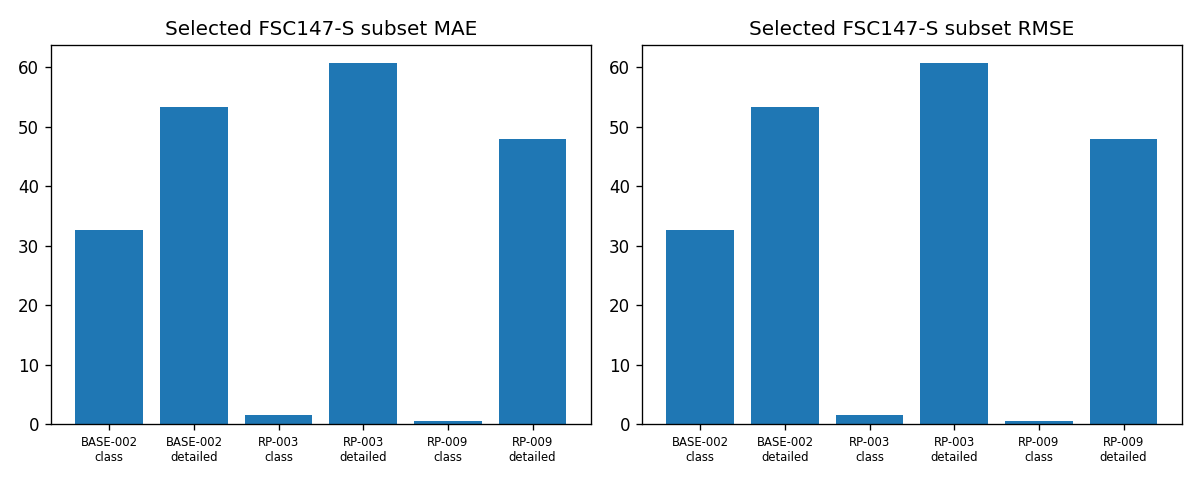

Figure: 3319__attention_patch00.png


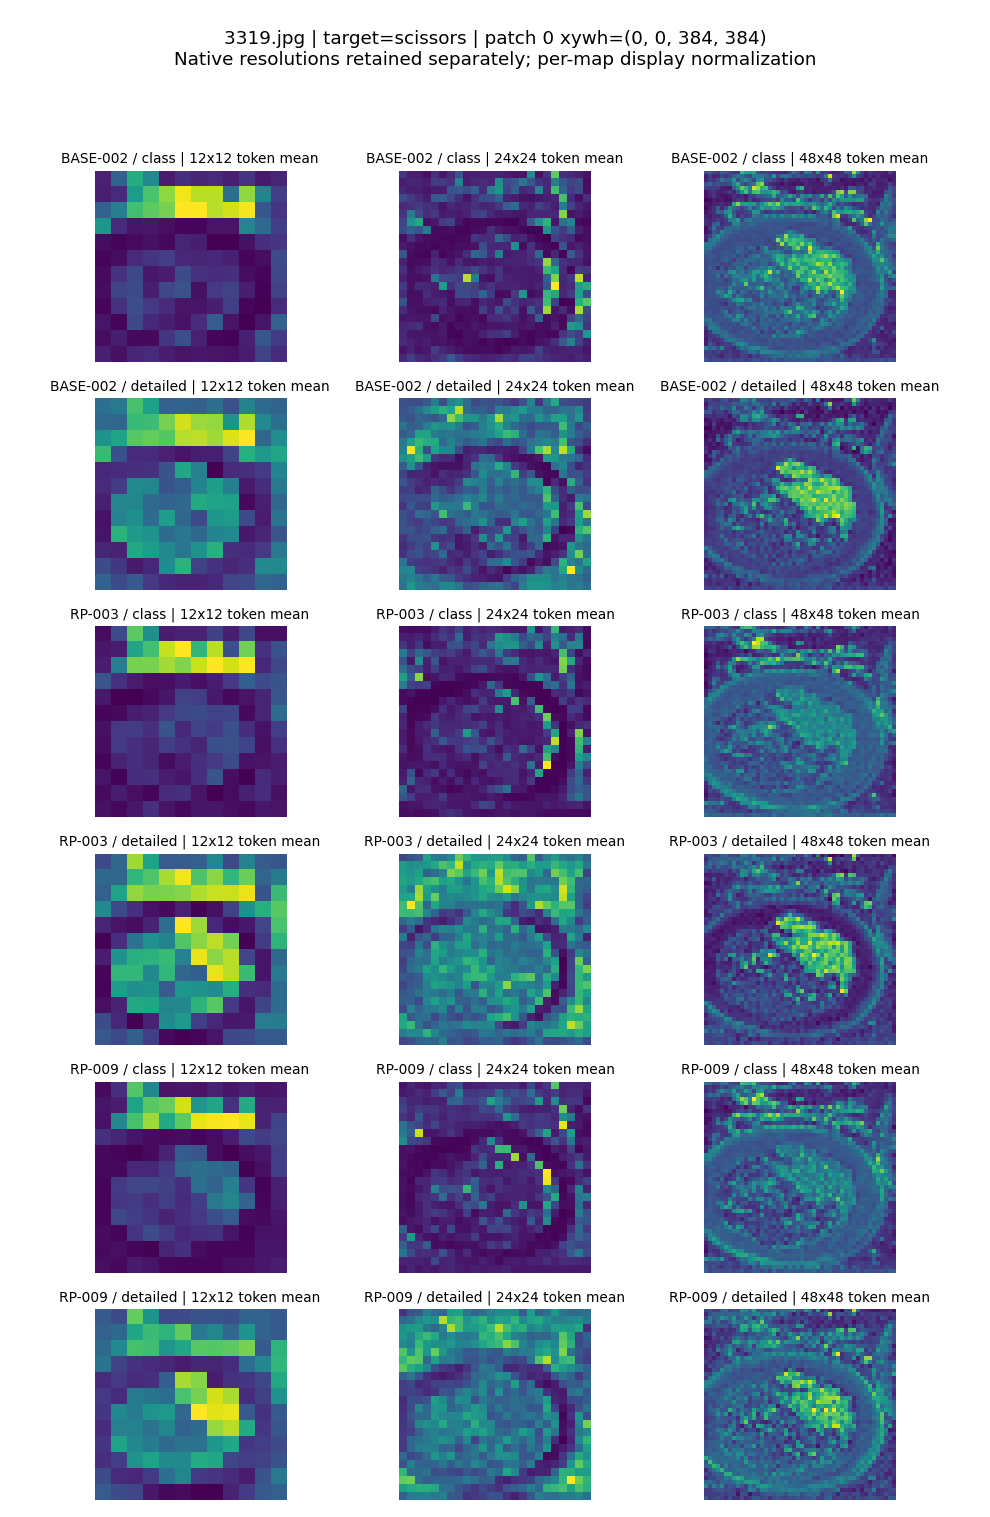

Figure: 3319__attention_patch01.png


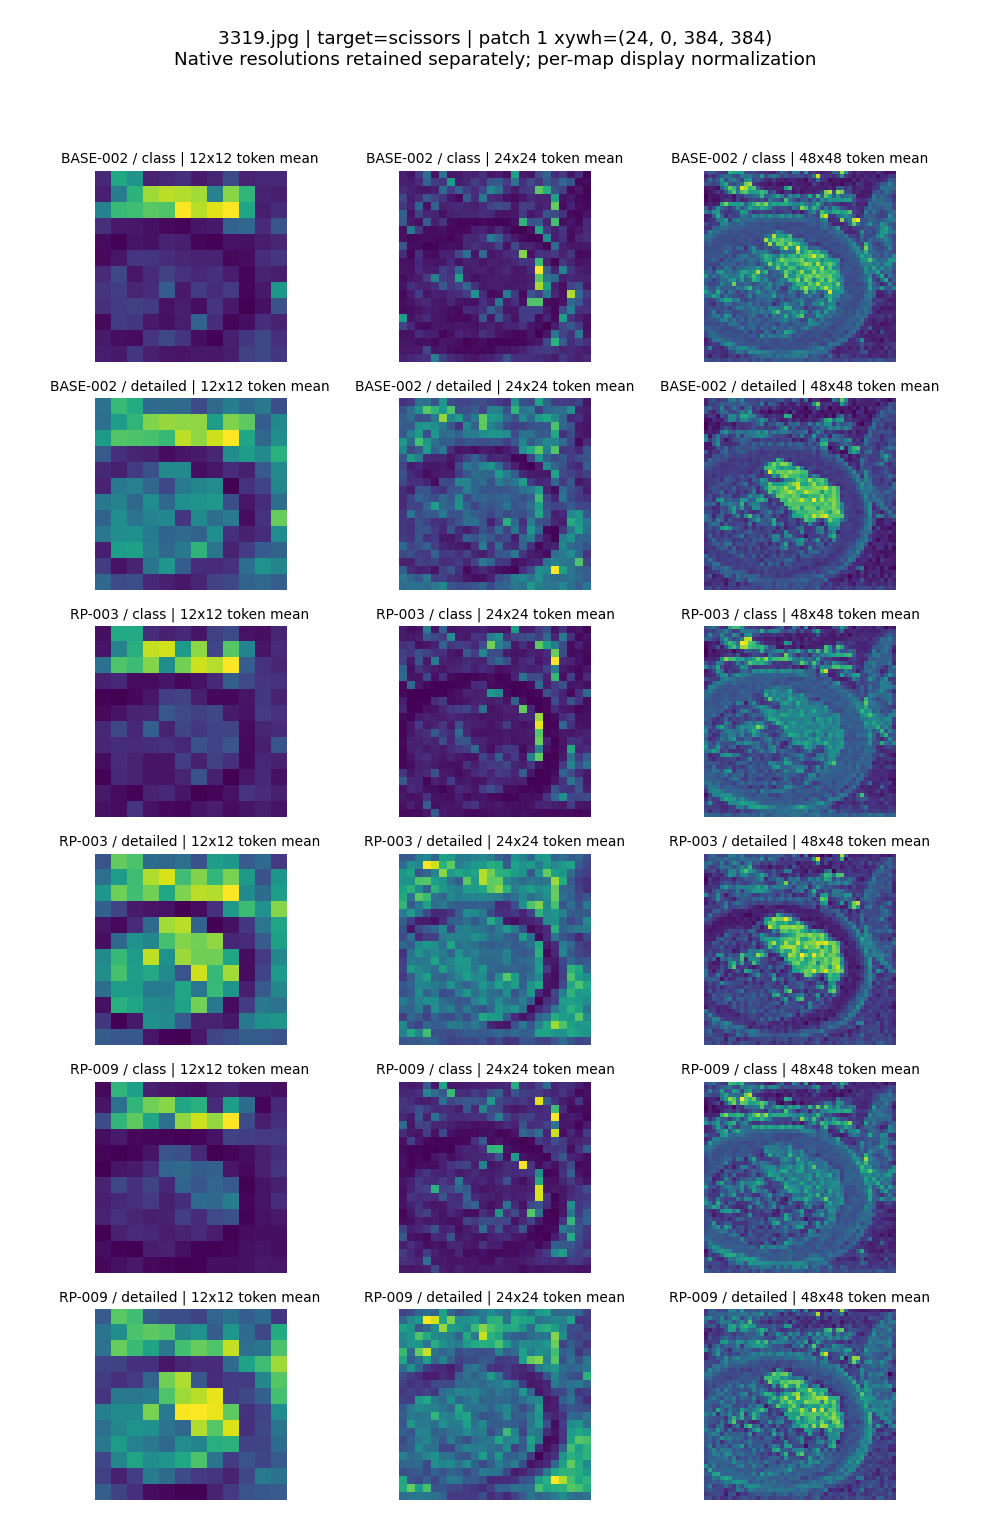

Figure: 3319__full_density.png


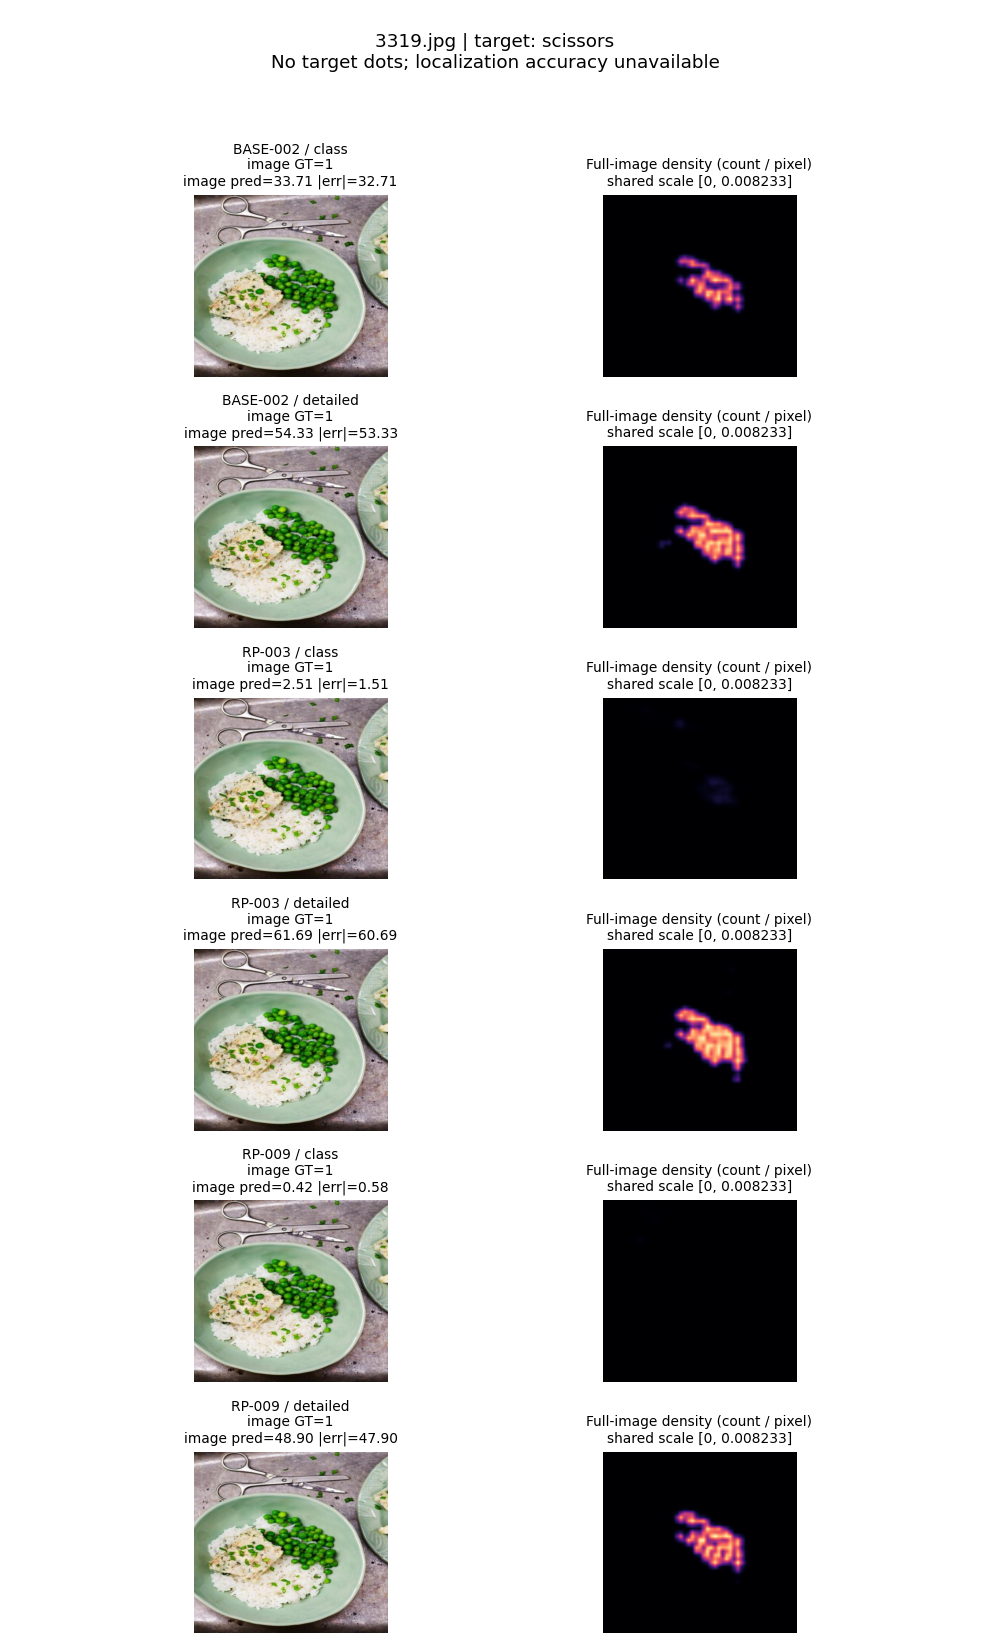

Figure: 3319__patch00.png


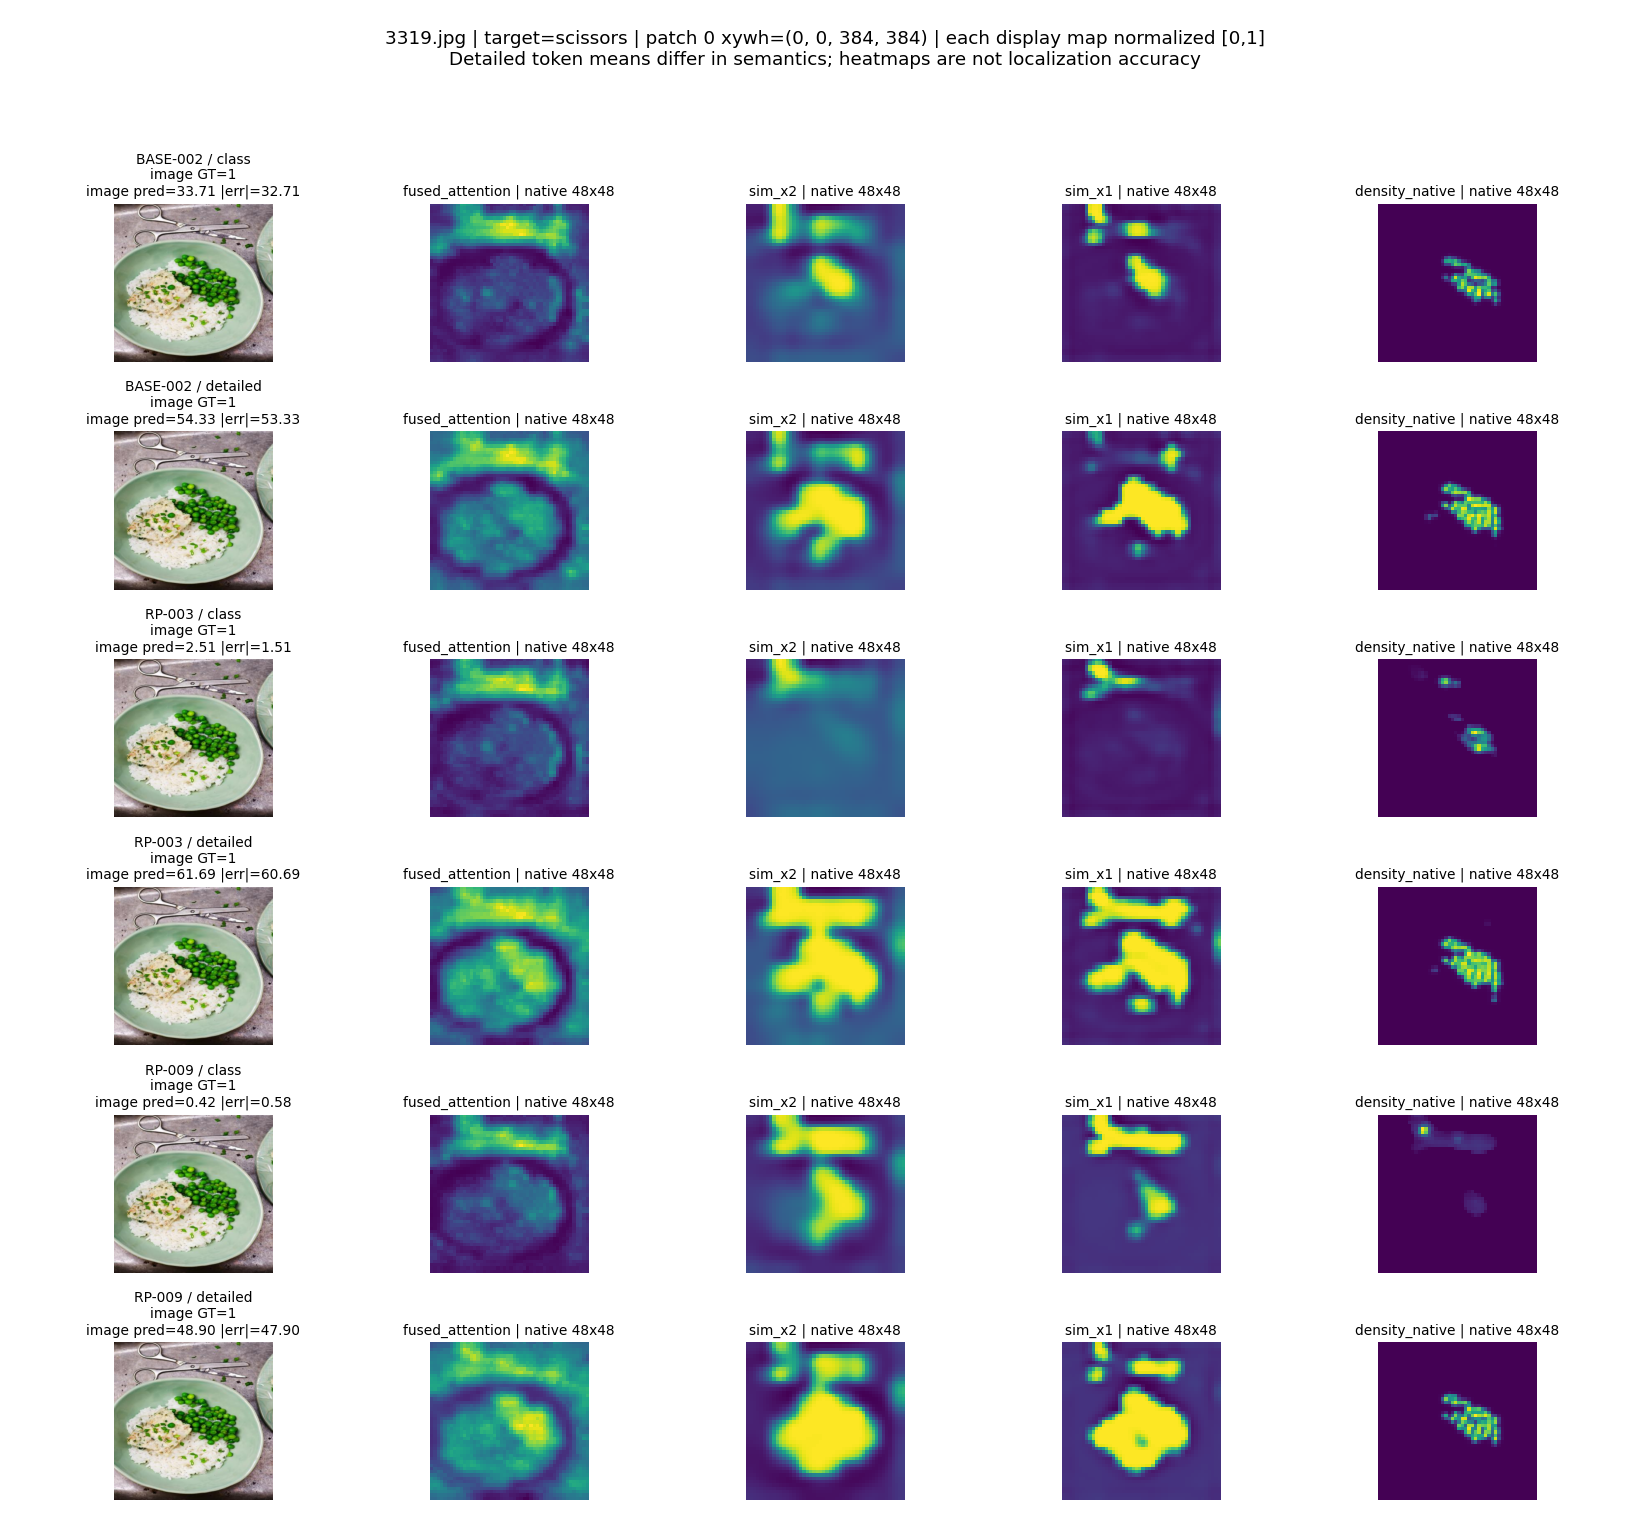

Figure: 3319__patch01.png


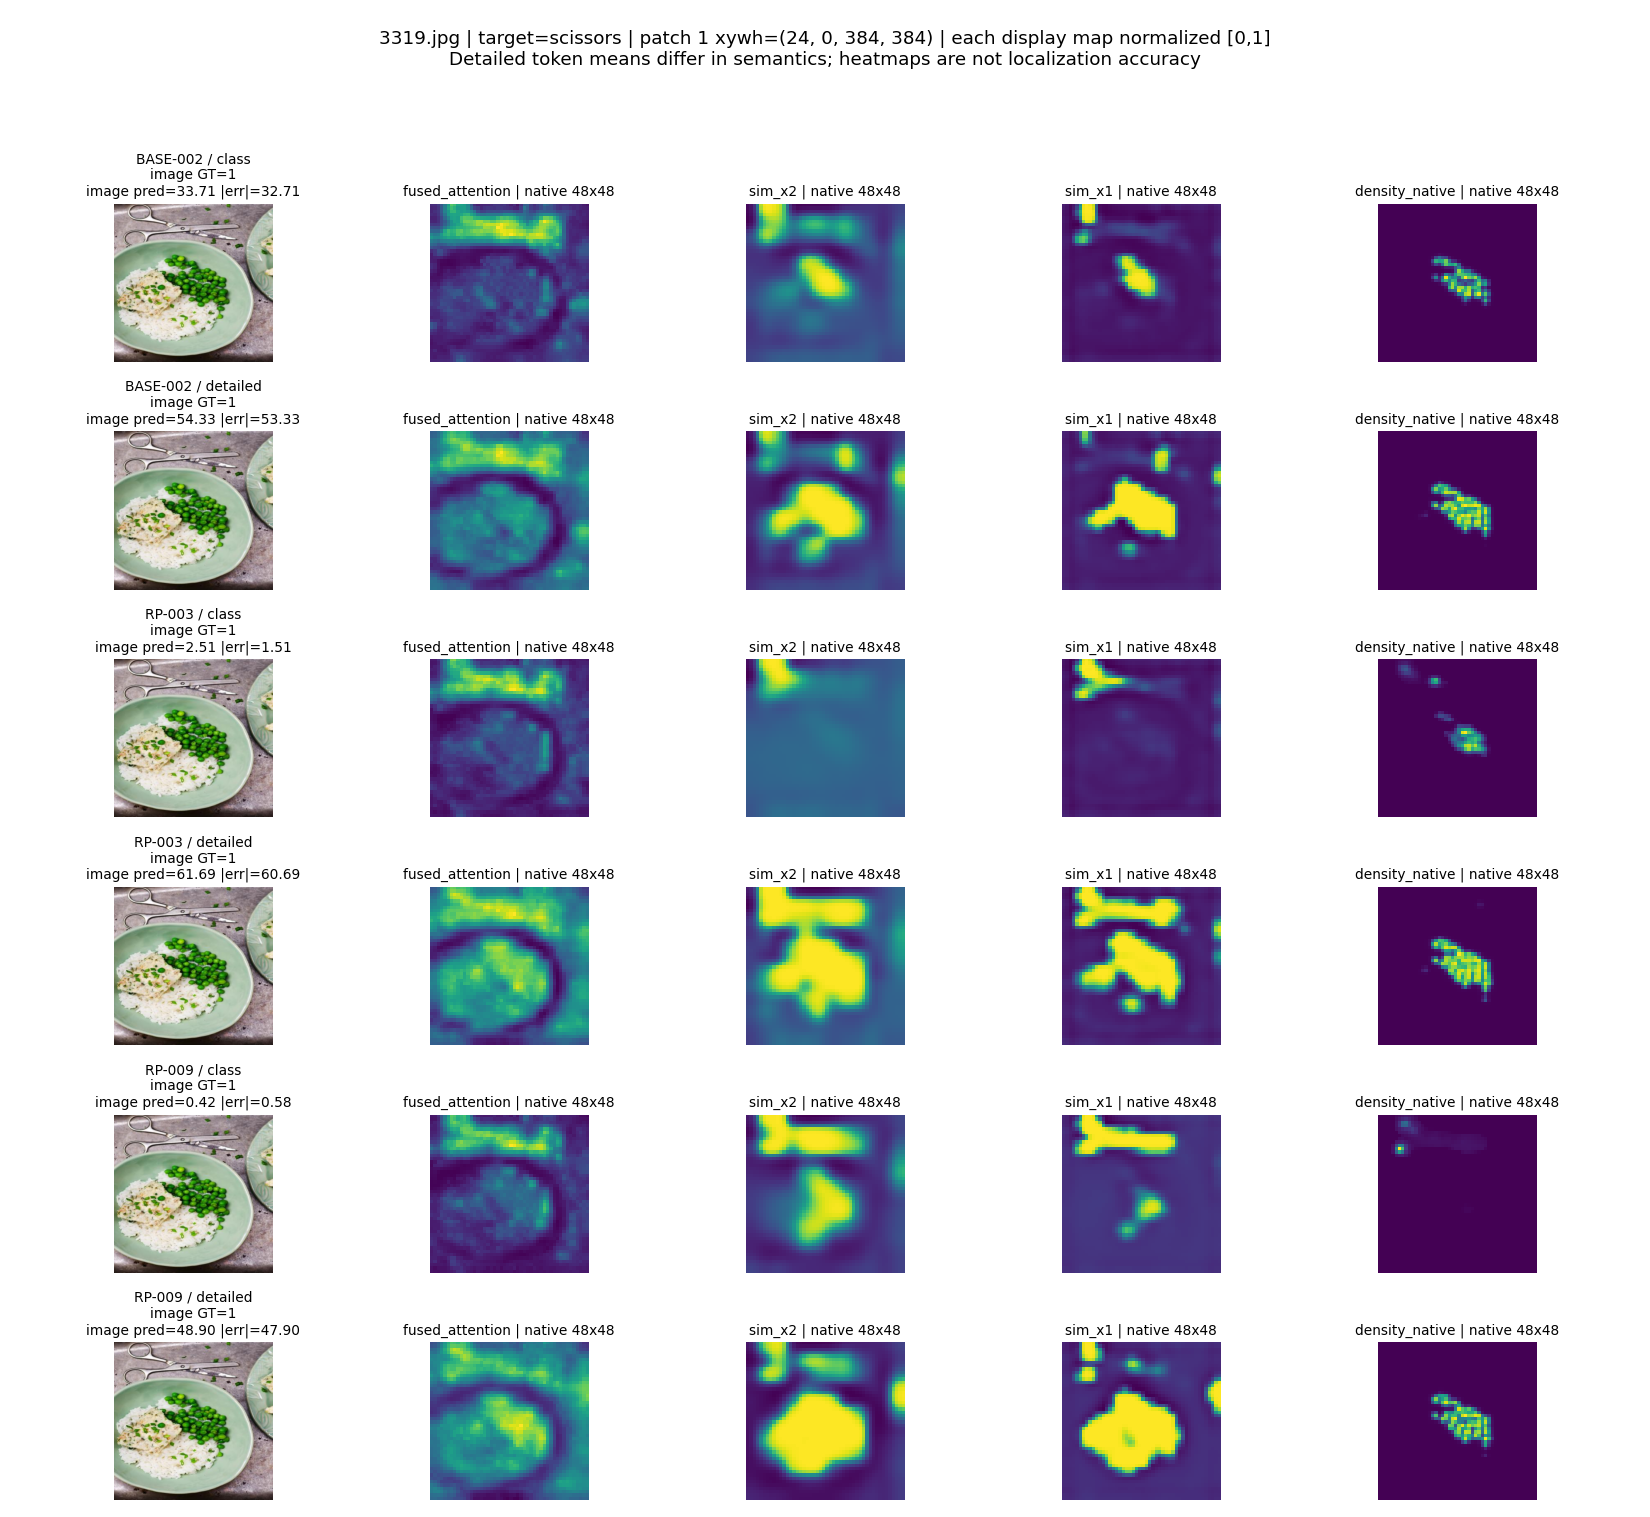


=== FULL DIAGNOSTIC ===
Folder: /content/drive/MyDrive/T2ICount-assets/outputs/spatial_diagnostic_v2_all230
Validation: complete: 230 images, 1380 conditions, 6 designated-image capture checks
First-image capture equivalence: 6 / 6 bitwise equal
Images: 230 | first 20: ['3319.jpg', '7706.jpg', '918.jpg', '31.jpg', '605.jpg', '290.jpg', '343.jpg', '336.jpg', '6305.jpg', '3169.jpg', '6353.jpg', '3721.jpg', '3699.jpg', '3019.jpg', '5651.jpg', '63.jpg', '3287.jpg', '75.jpg', '3703.jpg', '5356.jpg']
BASE-002 class    n=230 MAE=33.5840 RMSE=52.7412
BASE-002 detailed n=230 MAE=44.5114 RMSE=72.2839
RP-003   class    n=230 MAE=24.1215 RMSE=40.2698
RP-003   detailed n=230 MAE=44.7634 RMSE=77.0428
RP-009   class    n=230 MAE=14.2940 RMSE=24.8142
RP-009   detailed n=230 MAE=34.6743 RMSE=61.6167


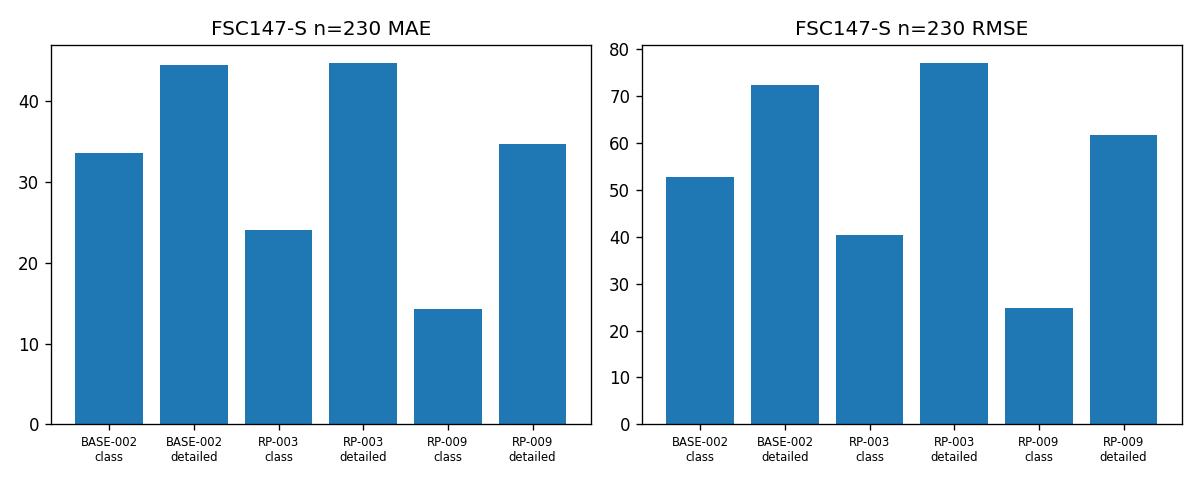

Figure: 290__attention_patch00.png


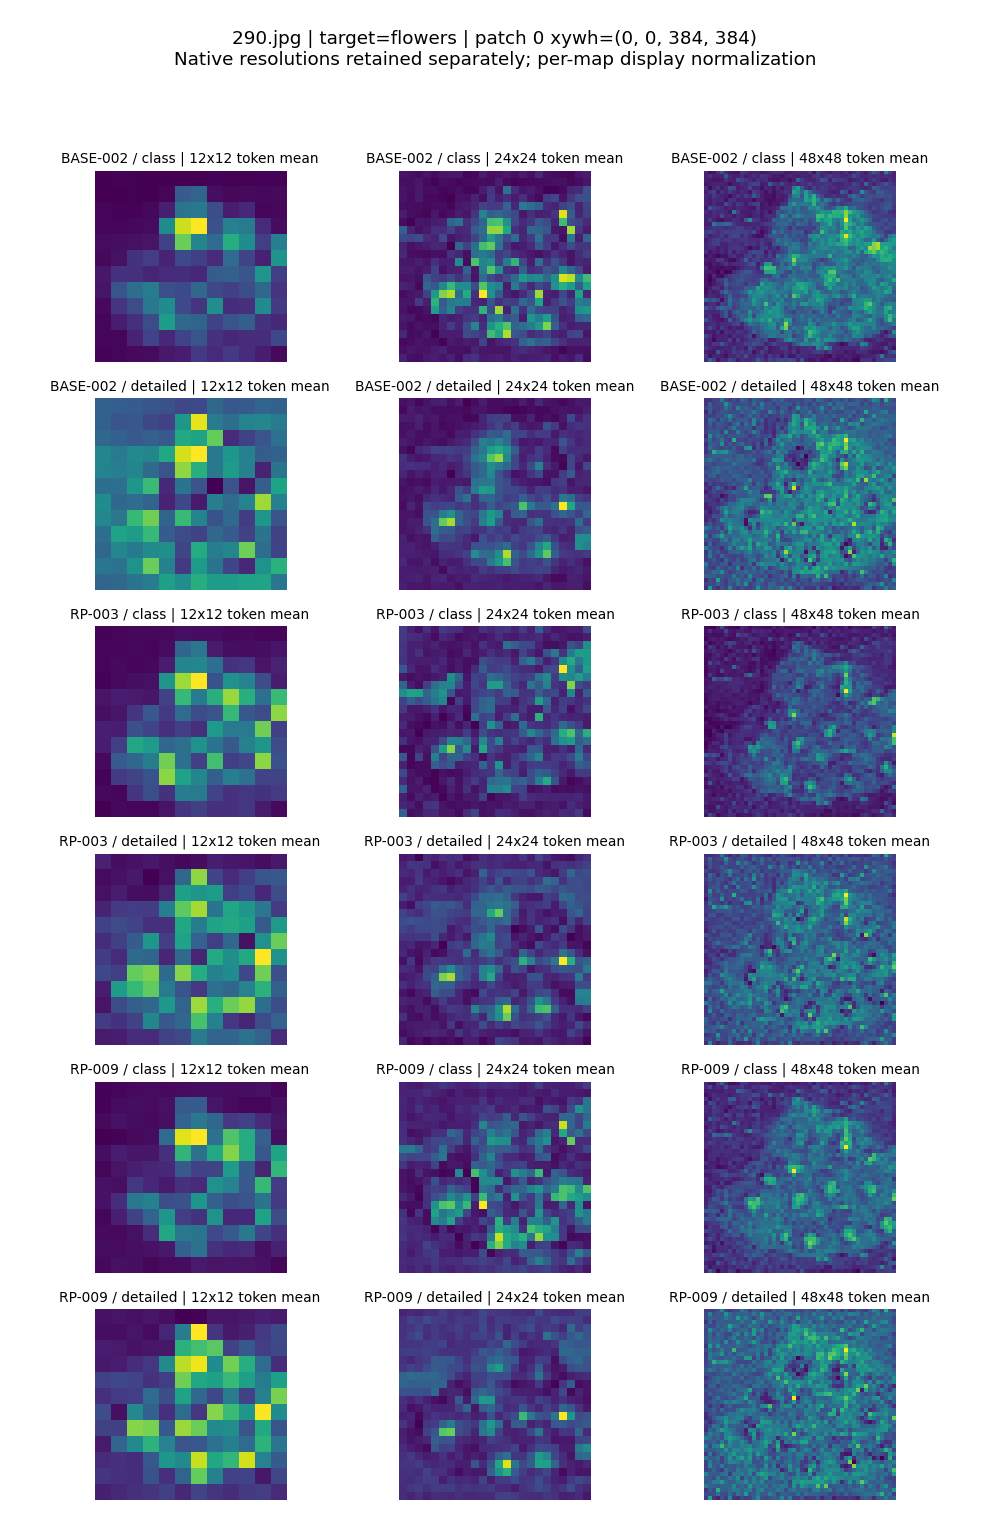

Figure: 290__attention_patch01.png


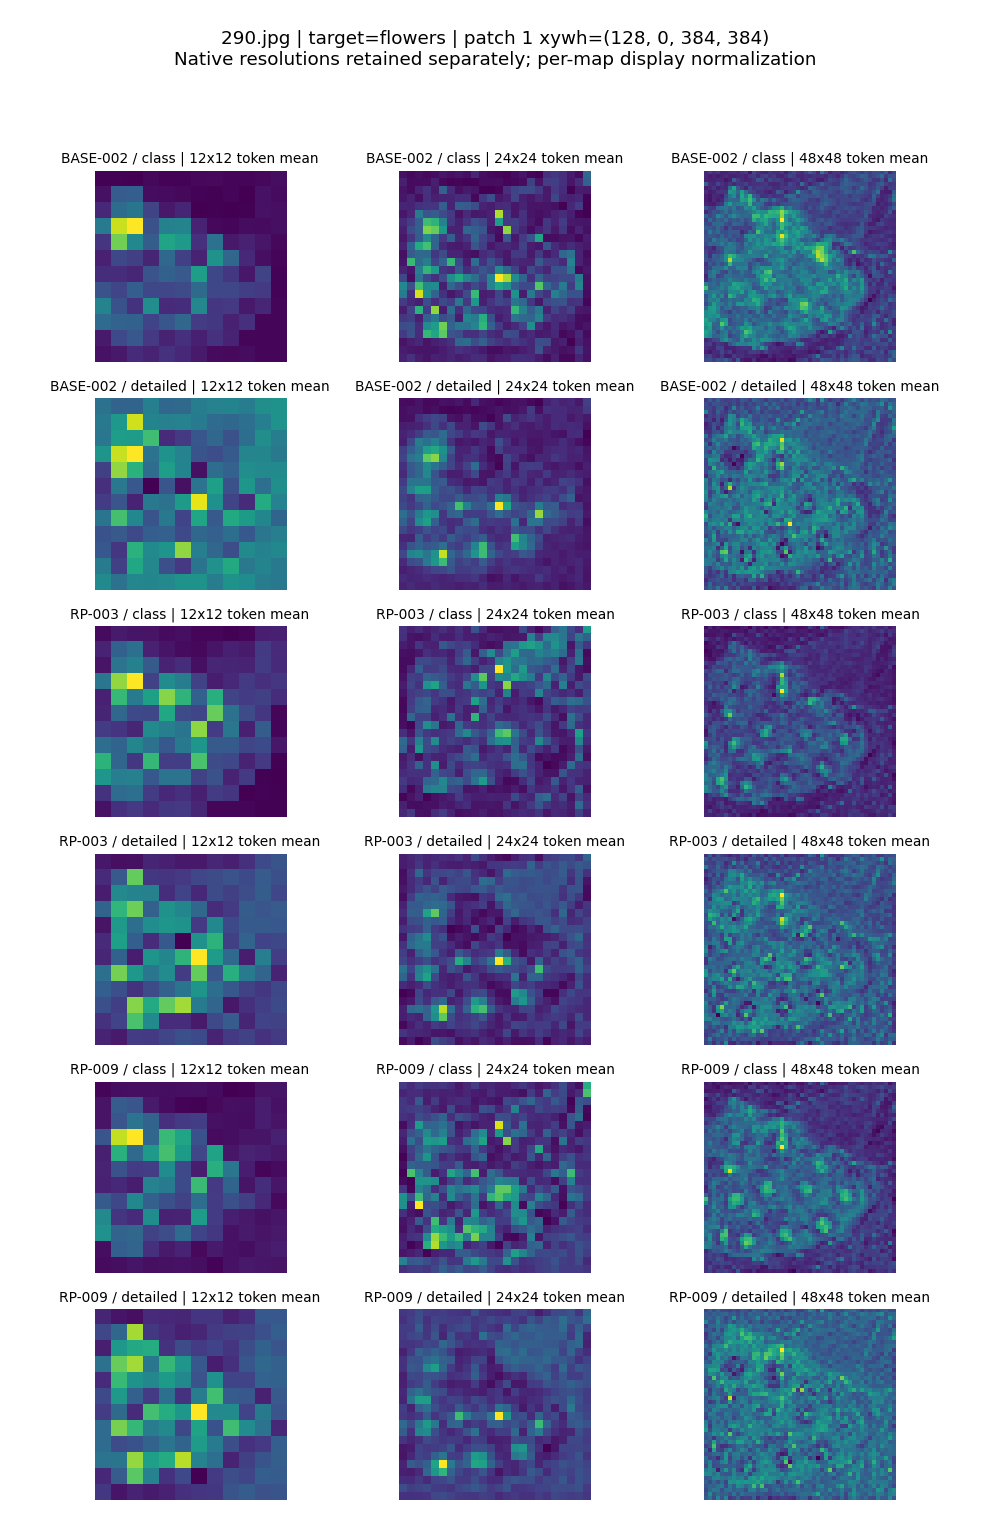

98 additional figures saved on Drive.


In [9]:
from IPython.display import display, Image as DisplayImage

def show_saved_report(folder, n_images, title, figure_limit=2):
    complete, reason = saved_run_state(folder, n_images)
    print(f'\n=== {title} ===')
    print('Folder:', folder)
    print('Validation:', reason)
    if not complete:
        if Path(folder).exists():
            print('Existing output is partial/inconsistent. Inspect run.log/manifest.json before retrying.')
        return
    manifest = json.loads((folder / 'manifest.json').read_text(encoding='utf-8'))
    summary = json.loads((folder / 'summary.json').read_text(encoding='utf-8'))
    print('First-image capture equivalence:', sum(c['bitwise_equal'] for c in manifest['capture_equivalence']),
          '/', len(manifest['capture_equivalence']), 'bitwise equal')
    print('Images:', len(manifest['selected_images']), '| first 20:',
          [r['image'] for r in manifest['selected_images'][:20]])
    for row in summary['counting']:
        print('{model:8s} {prompt_type:8s} n={n:2d} MAE={mae:.4f} RMSE={rmse:.4f}'.format(**row))
    summary_figure = folder / 'figures/summary.png'
    if summary_figure.is_file():
        display(DisplayImage(filename=str(summary_figure)))
    figures = [p for p in sorted((folder / 'figures').glob('*.png')) if p != summary_figure]
    for p in figures[:figure_limit]:
        print('Figure:', p.name)
        display(DisplayImage(filename=str(p)))
    if len(figures) > figure_limit:
        print(f'{len(figures) - figure_limit} additional figures saved on Drive.')

show_saved_report(PRELIMINARY_OUTPUT_DIR, 1, 'PRELIMINARY (one image)', figure_limit=6)
show_saved_report(OUTPUT_DIR, NUM_IMAGES, 'FULL DIAGNOSTIC', figure_limit=2)


## 8. Optional individual-token view (saved full results only)

No inference is run. This helper loads the original CLIP sequence positions from the saved full diagnostic.


In [10]:
SHOW_TOKEN = False
if SHOW_TOKEN:
    assert OUTPUT_DIR.joinpath("manifest.json").is_file(), "No full diagnostic to inspect"
    assert REPO.exists(), "Token view needs source restored. Run setup or use the original notebook."
    from tools.spatial_diagnostic import plot_token
    import matplotlib.pyplot as plt
    manifest = json.loads((OUTPUT_DIR / 'manifest.json').read_text())
    image_record = manifest['selected_images'][0]
    model_name = MODEL_SELECTION[0]
    prompt_mode = 'detailed' if 'detailed' in PROMPT_SELECTION else 'class'
    token_info = image_record['prompts'][prompt_mode]
    print([(i, token_info['tokens'][i]) for i in token_info['active_token_indices']])
    TOKEN_POSITION = token_info['active_token_indices'][0]
    figure = plot_token(OUTPUT_DIR, image_record['image'], model_name, prompt_mode,
                        TOKEN_POSITION, patch_index=0)
    display(figure)
    plt.close(figure)


## Outputs and interpretation

- All 230 images: results.csv, map_comparisons.csv and summary.json.
- Original 20 only: full/native intermediate NPZs and detailed figures; summary.png
  shows full-230 counting metrics. Native patch coordinates/resolutions are unchanged.
- Temporary maps stay on local runtime disk and are cleaned; completion requires the
  cache to be removed. Existing output directories are never overwritten.
- Six capture-equivalence checks on 3319.jpg (each model/prompt); all conditions still
  require counting and intermediate-map metrics. This notebook validates exact coverage.
- Class inference is primary; detailed prompts and heatmap differences are diagnostic.
  Dot localization metrics remain unavailable. No causal or localization-accuracy claim.
- This notebook has not established a real-model GPU result during local CPU testing.
  Runtime manifests record the actual Git commit, assets, environment and safety checks.
